# S³ semantic-axis smoke test

This exploratory test fits Turftopic S³ to the existing semantic passages using the saved BGE-M3 vectors. Passage embeddings are loaded from disk and passed through `embeddings=`; they are not recomputed. The matching local BGE model is used only for vocabulary-term embeddings.

This fit uses 20 components and seed 42. Scores are signed ICA coordinates, not calibrated probabilities or BERTopic topics. Review the displayed positive/negative evidence before interpreting an axis. Original BERTopic assignments are not changed.

Run from the repository root with `uv run --group topic-analysis jupyter lab`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from turftopic import SemanticSignalSeparation

project_root = Path.cwd().resolve()
if not (project_root / 'data/topic-analysis').exists():
    project_root = project_root.parent
if not (project_root / 'data/topic-analysis').exists():
    raise FileNotFoundError('Could not locate data/topic-analysis from the notebook working directory')
results = project_root / 'data/topic-analysis/results'
dataset_path = results / 'segment-dataset/all-segments.parquet'
embedding_path = results / 'jev-semantic-all/bubble-maps/segment-embeddings.npy'
embedding_manifest_path = results / 'jev-semantic-all/bubble-maps/embedding-manifest.json'
model_manifest_path = results / 'segment-dataset/manifest.json'
MODEL_ID = 'BAAI/bge-m3'
MODEL_REVISION = '5617a9f61b028005a4858fdac845db406aefb181'
N_COMPONENTS, RANDOM_STATE = 20, 42
print(f'Project: {project_root}')
print(f'Saved vectors: {embedding_path}')

Project: C:\Users\risto\projects\arvamusfestivali_salvestused
Saved vectors: C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\bubble-maps\segment-embeddings.npy


C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\_snmf.py:20: UserWarning: JAX not found, continuing with NumPy implementation.
  warnings.warn("JAX not found, continuing with NumPy implementation.")


In [2]:
wanted = ['segment_key', 'segmentation', 'passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength']
available = set(pd.read_parquet(dataset_path).columns)
all_passages = pd.read_parquet(dataset_path, columns=[c for c in wanted if c in available])
passages = all_passages.loc[all_passages.segmentation == 'semantic'].reset_index(drop=True)
embedding_manifest = json.loads(embedding_manifest_path.read_text(encoding='utf-8'))
model_info = json.loads(model_manifest_path.read_text(encoding='utf-8'))['models']['semantic']
embeddings = np.load(embedding_path, allow_pickle=False)
assert model_info['embedding_model_id'] == MODEL_ID
assert model_info['embedding_revision'] == MODEL_REVISION
assert int(model_info['embedding_dimension']) == 1024
assert passages.segment_key.tolist() == embedding_manifest['segment_keys'], 'Passage/vector order mismatch'
assert embeddings.shape == (len(passages), 1024), embeddings.shape
assert embeddings.dtype == np.float32 and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4), 'Vectors are not L2-normalized'
print(f'Validated {len(passages):,} passages × {embeddings.shape[1]} dimensions; float32, finite, L2-normalized.')
print(f"Model: {model_info['embedding_model_id']} @ {model_info['embedding_revision']}")
print(f"Original BERTopic outliers (topic -1): {(passages.topic_id == -1).sum():,}")

Validated 4,132 passages × 1024 dimensions; float32, finite, L2-normalized.
Model: BAAI/bge-m3 @ 5617a9f61b028005a4858fdac845db406aefb181
Original BERTopic outliers (topic -1): 827


## Fit on the precomputed vectors

The encoder is loaded from local cache only. If that exact revision is not cached, the cell fails instead of downloading or substituting another model. Turftopic receives the corpus matrix directly via `embeddings=embeddings`.

In [3]:
encoder = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, local_files_only=True)
s3 = SemanticSignalSeparation(n_components=N_COMPONENTS, encoder=encoder, vectorizer=CountVectorizer(max_features=500), random_state=RANDOM_STATE)
scores = s3.fit_transform(passages.text.tolist(), embeddings=embeddings)
assert scores.shape == (len(passages), N_COMPONENTS), scores.shape
assert np.isfinite(scores).all(), 'S³ scores contain non-finite values'
score_columns = [f's3_component_{i}' for i in range(N_COMPONENTS)]
scored_passages = passages.copy()
for i, column in enumerate(score_columns):
    scored_passages[column] = scores[:, i]
print(f'S³ fit passed: {len(passages):,} passages, {N_COMPONENTS} components, seed {RANDOM_STATE}.')
print('Passage vectors came from disk; no passage re-embedding was run.')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Output()

C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\sklearn\decompositio
n\_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum 
number of iterations.
  warnings.warn(

[18:25:48] Decomposition done.                                                                        ]8;id=610958;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=907459;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#156\156]8;;\

[18:25:51] Term extraction done.                                                                      ]8;id=839808;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=185306;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#159\159]8;;\

[18:25:57] Vocabulary encoded.                                                                        ]8;id=850623;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=810234;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#169\169]8;;\

           Model fitting done.                                                                        ]8;id=567919;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=739223;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#189\189]8;;\

S³ fit passed: 4,132 passages, 20 components, seed 42.
Passage vectors came from disk; no passage re-embedding was run.


## S³ component summary and naming evidence

S³ returns continuous bipolar axes, not discrete topic assignments. The dominant-axis count below is only an exploratory tally: each passage is counted under the component with its largest absolute standardized score. It is not a cluster count or a calibrated classification. For naming, review Turftopic's high/low term lists alongside the positive/negative extreme passages below, then enter a human-reviewed bipolar label; no labels are generated automatically.

In [4]:
score_frame = pd.DataFrame(scores, columns=score_columns)
score_std = score_frame.std(ddof=0).replace(0, 1)
score_z = (score_frame - score_frame.mean()) / score_std
dominant_component_index = np.abs(score_z.to_numpy()).argmax(axis=1)
dominant_counts = pd.Series(dominant_component_index).value_counts().reindex(range(N_COMPONENTS), fill_value=0)
positive_terms = s3.get_top_words(top_k=12, positive=True)
negative_terms = s3.get_top_words(top_k=12, positive=False)

component_stats = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'passage_count': len(score_frame),
    'score_nan_count': score_frame.isna().sum().to_numpy(),
    'positive_score_count': score_frame.gt(0).sum().to_numpy(),
    'negative_score_count': score_frame.lt(0).sum().to_numpy(),
    'mean_score': score_frame.mean().to_numpy(),
    'score_std': score_frame.std(ddof=0).to_numpy(),
    'min_score': score_frame.min().to_numpy(),
    'max_score': score_frame.max().to_numpy(),
    'dominant_axis_passages_exploratory': dominant_counts.to_numpy(),
})
print(f'S³ passages scored: {len(score_frame):,}; missing passage texts: {passages.text.isna().sum():,}; blank passage texts: {(passages.text.notna() & passages.text.astype("string").str.strip().eq("")).sum():,}')
print('Continuous score distribution and exploratory dominant-axis counts (not topic membership)')
display(component_stats)

axis_review = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'positive_end_terms': [', '.join(words) for words in positive_terms],
    'negative_end_terms': [', '.join(words) for words in negative_terms],
    'reviewed_bipolar_label': ['' for _ in range(N_COMPONENTS)],
    'review_notes': ['' for _ in range(N_COMPONENTS)],
})
print('Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.')
display(axis_review)
assert int(component_stats.passage_count.iloc[0]) == len(passages)
assert int(component_stats.score_nan_count.sum()) == int(score_frame.isna().sum().sum())
assert int(component_stats.dominant_axis_passages_exploratory.sum()) == len(passages)
print(f"S3_COMPONENT_STATS_OK passages={len(passages):,}; components={N_COMPONENTS}; missing_scores={int(score_frame.isna().sum().sum())}")

S³ passages scored: 4,132; missing passage texts: 0; blank passage texts: 0
Continuous score distribution and exploratory dominant-axis counts (not topic membership)


,component_id,passage_count,score_nan_count,positive_score_count,negative_score_count,mean_score,score_std,min_score,max_score,dominant_axis_passages_exploratory
0,0,4132,0,2090,2042,-1.966434e-07,1.0,-3.113055,2.644674,120
1,1,4132,0,2261,1871,5.539250e-08,1.0,-4.892195,2.762013,174
2,2,4132,0,1955,2177,-3.249694e-07,1.0,-3.121947,5.591216,198
3,3,4132,0,2050,2082,2.067987e-07,1.0,-2.857558,3.221203,181
4,4,4132,0,1720,2412,8.493517e-08,1.0,-2.554327,4.608782,254
5,5,4132,0,2442,1690,-1.366349e-07,1.0,-4.835110,2.236602,196
6,6,4132,0,2366,1766,3.729762e-07,1.0,-5.310563,2.402187,217
7,7,4132,0,2082,2050,-4.689899e-07,1.0,-4.314069,3.238360,188
8,8,4132,0,1691,2441,-5.539250e-08,1.0,-2.261733,4.655221,229
9,9,4132,0,1827,2305,-2.954267e-08,1.0,-3.042401,4.812300,244


Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.


,component_id,positive_end_terms,negative_end_terms,reviewed_bipolar_label,review_notes
0,0,"noor, raha, noh, head, inimene, mõte, eriti, e...","ütlesid, olid, ütleks, olnud, võiks, mõned, pe...",,
1,1,"ei, täna, riik, no, ütlesid, suhtes, eesti, ko...","raha, palju, kokku, lisaks, mille, juurde, hak...",,
2,2,"vastu, riigi, tööle, teen, riik, saa, ennast, ...","selle, selge, mitu, selles, sellele, leida, se...",,
3,3,"mõtlema, mõttes, ennast, noh, inimese, niisugu...","riik, riigi, lapsed, protsenti, tööle, aasta, ...",,
4,4,"hetkel, ega, olete, oled, koht, selgelt, kodus...","inimeste, sõna, riigi, inimesed, inimesi, inim...",,
5,5,"no, võimalik, põhimõtteliselt, ikkagi, öelda, ...","kelle, kes, oleme, olen, teeme, tean, olin, te...",,
6,6,"tahaks, arvan, parem, kindlasti, edasi, tuleva...","töö, tööd, tööle, jooksul, probleem, puhul, jä...",,
7,7,"lahti, kellel, vastu, puhul, no, juures, kooli...","kakskümmend, kolmkümmend, aastat, protsenti, i...",,
8,8,"ai, it, asi, id, alati, aeg, aitäh, inimest, s...","kooli, mulle, sul, mõju, koolis, eks, suur, ol...",,
9,9,"kuhu, ümber, koht, juurde, taga, juures, id, k...","ütles, ma, oli, euroopa, mina, panna, küsimuse...",,


S3_COMPONENT_STATS_OK passages=4,132; components=20; missing_scores=0


## 2-D view of the S³ axes

Each panel shows the same passage map: a PCA projection of the already-saved embeddings. Color shows the signed standardized S³ score for that panel's axis; outlined points are original BERTopic outliers (`topic_id == -1`). The map is only a 2-D projection and does not define clusters or topics.

The table below gives one strongest positive and negative evidence passage per axis, alongside top terms. These are evidence for human review, not automatic topic names.

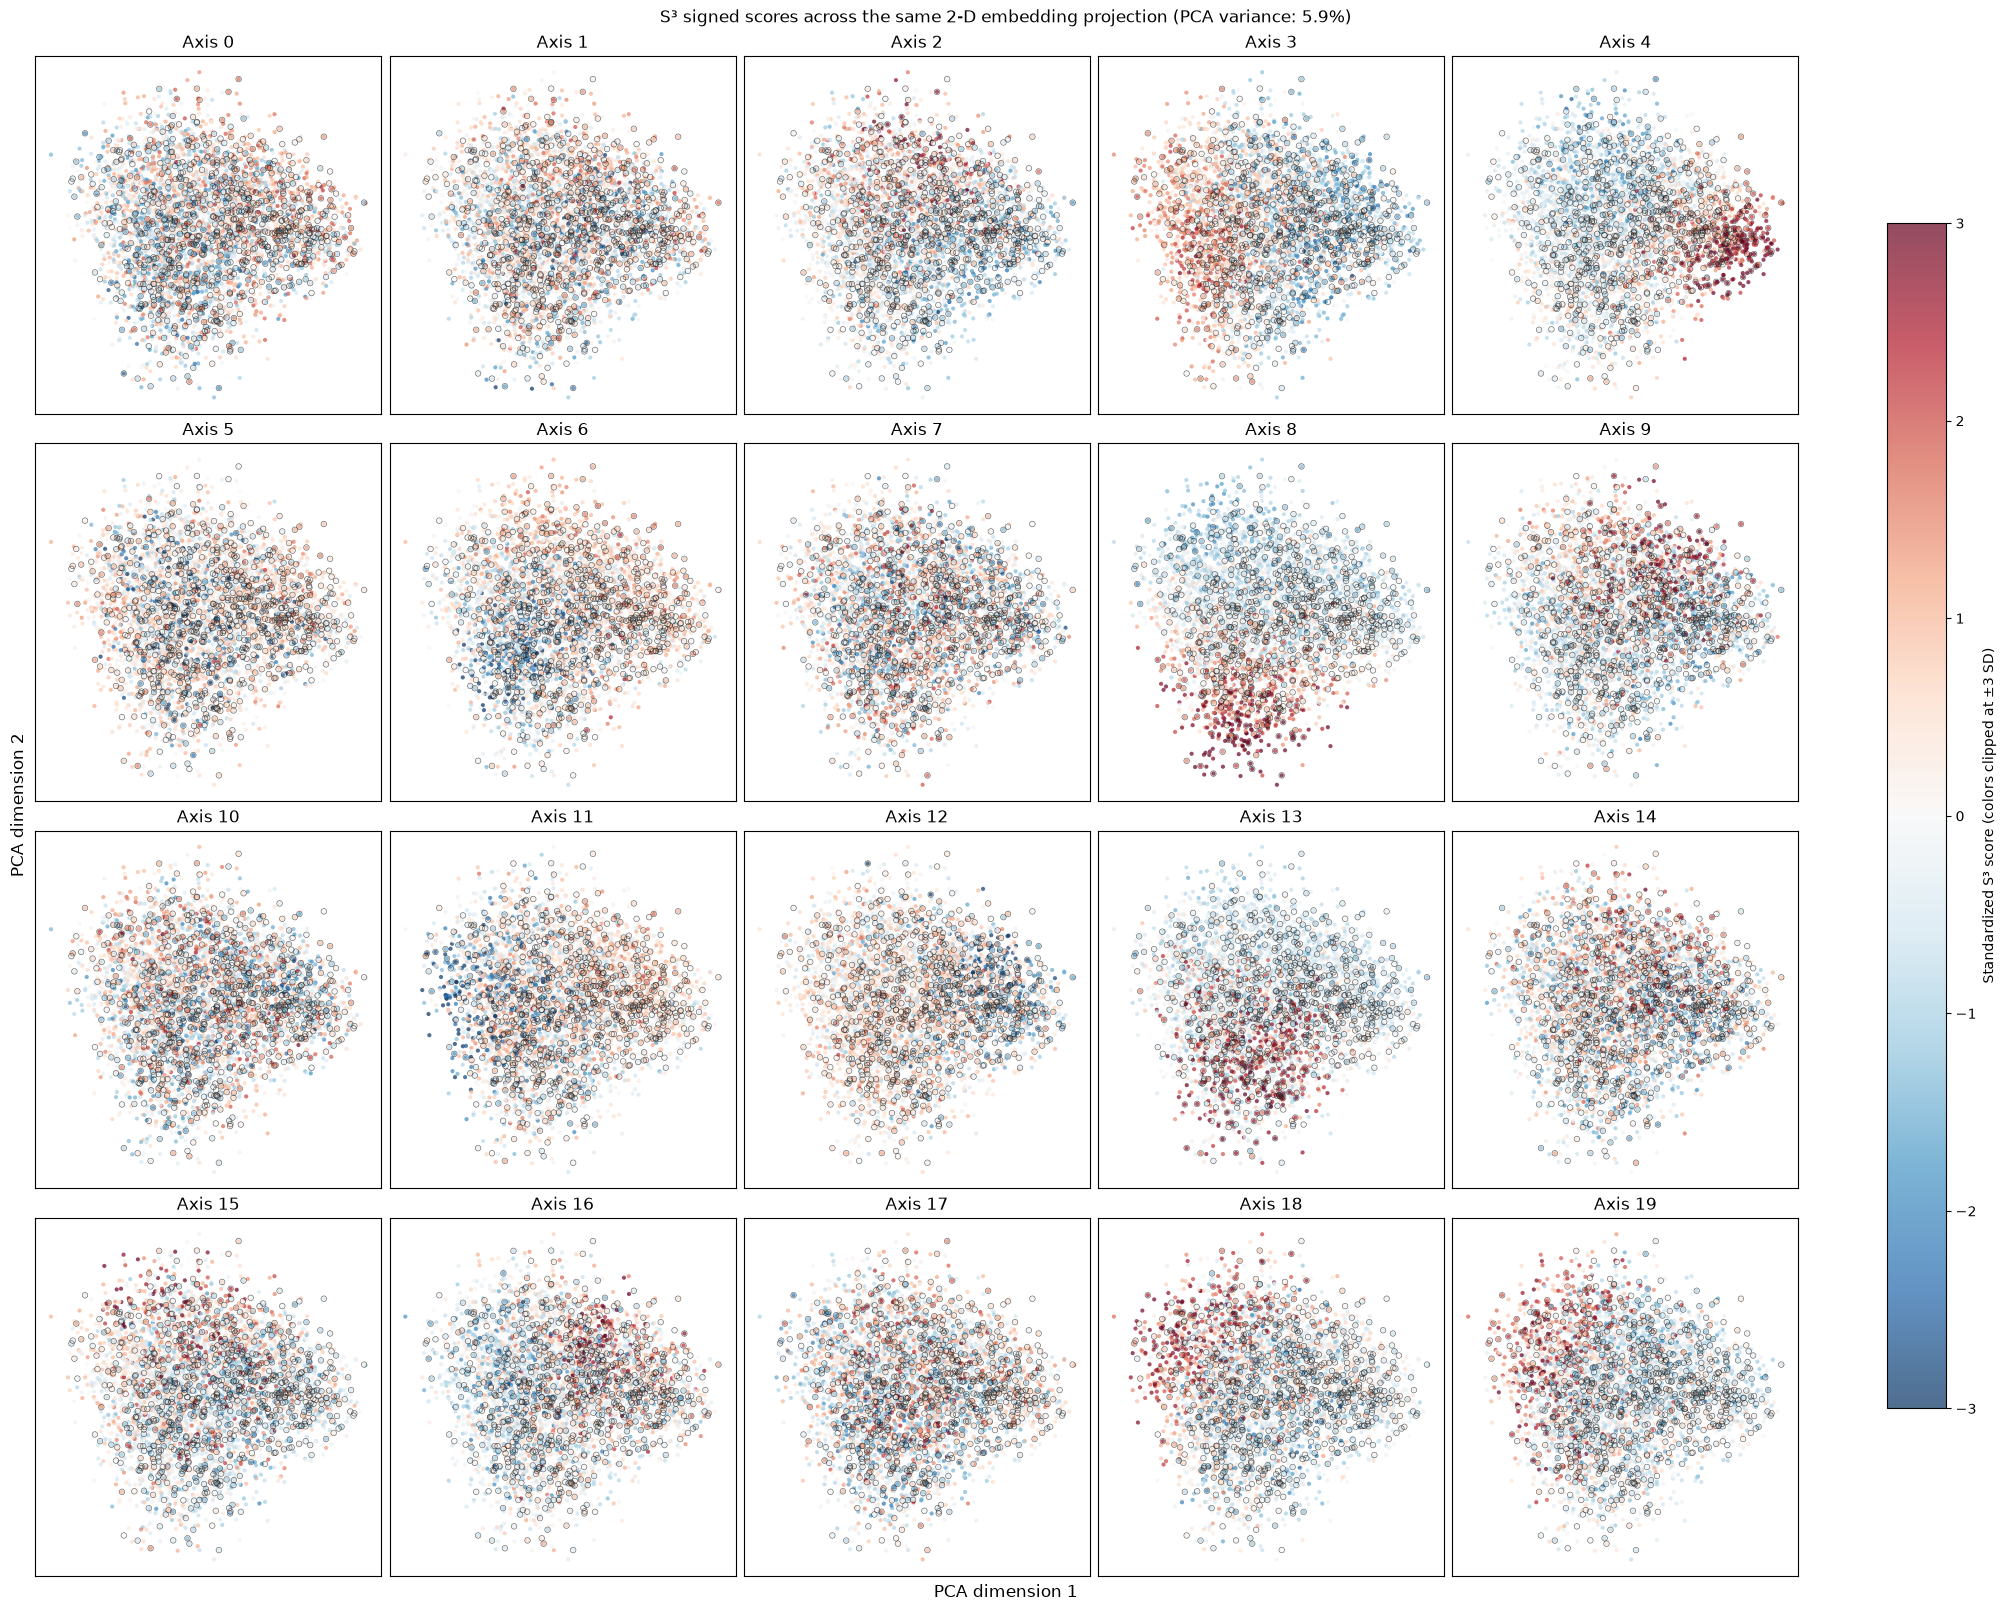

2-D projection uses the saved 1024-D vectors for 4,132 passages; BERTopic outliers outlined: 827.
Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.


,axis,positive terms,positive passage,negative terms,negative passage
0,0,"noor, raha, noh, head, inimene, mõte, eriti, ees",2247188702 | Kuidas juhtida riiki? Visiooni põ...,"ütlesid, olid, ütleks, olnud, võiks, mõned, pe...",2396692752 | Tuleviku Eesti edulugu_ majandusk...
1,1,"ei, täna, riik, no, ütlesid, suhtes, eesti, kodus",2395991451 | Kas lapsed maksavad karjääris kät...,"raha, palju, kokku, lisaks, mille, juurde, hak...",2300040503 | Annetuskultuur. Kuidas Eestist sa...
2,2,"vastu, riigi, tööle, teen, riik, saa, ennast, ...",2271676352 | Ajalugu oleviku teejuhina – krist...,"selle, selge, mitu, selles, sellele, leida, se...",2254333409 | Kust tuleb raha aastal 2040_ | 24...
3,3,"mõtlema, mõttes, ennast, noh, inimese, niisugu...",2383011942 | Kuidas hoida tervet mõistust krii...,"riik, riigi, lapsed, protsenti, tööle, aasta, ...",2247188687 | Kes koristab?! | 1094.72–1531.72s...
4,4,"hetkel, ega, olete, oled, koht, selgelt, kodus...",2302899431 | Kas elekter lahendab tulevikus kõ...,"inimeste, sõna, riigi, inimesed, inimesi, inim...",2258666738 | Mitmekultuuriline maailm Eesti ko...
5,5,"no, võimalik, põhimõtteliselt, ikkagi, öelda, ...",2397264588 | Mille taha jääb majanduskasv_ | 1...,"kelle, kes, oleme, olen, teeme, tean, olin, tere","2254333406 | Kuhu pöörad, rohepööre_ | 110.92–..."
6,6,"tahaks, arvan, parem, kindlasti, edasi, tuleva...",2393585469 | Mida Eesti tegelikult kõrgharidus...,"töö, tööd, tööle, jooksul, probleem, puhul, jä...",2247188693 | Töökius otse laval | 854.4–1248.7...
7,7,"lahti, kellel, vastu, puhul, no, juures, kooli...",2397264576 | Kas linnud ja loomad keedavad mei...,"kakskümmend, kolmkümmend, aastat, protsenti, i...",2400207750 | Eesti terviseandmed_ kristallkuul...
8,8,"ai, it, asi, id, alati, aeg, aitäh, inimest","2400184983 | Post-it, pastakas ja AI-agent - E...","kooli, mulle, sul, mõju, koolis, eks, suur, ol...","2396670933 | Kui pole mugav, siis ei kaasa_! |..."
9,9,"kuhu, ümber, koht, juurde, taga, juures, id, kogu",2396670927 | Kodude kättesaadavus_ kas Eestil ...,"ütles, ma, oli, euroopa, mina, panna, küsimuse...",2271676361 | “Kogu rahvas peab sõda. Sõjavägi ...


In [5]:
projection = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit_transform(embeddings)
assert projection.shape == (len(passages), 2) and np.isfinite(projection).all()
projection_variance = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit(embeddings).explained_variance_ratio_.sum()
outlier_mask = passages.topic_id.eq(-1).to_numpy()
ncols = min(5, N_COMPONENTS)
nrows = (N_COMPONENTS + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), sharex=True, sharey=True, constrained_layout=True)
axes = np.asarray(axes).reshape(-1)
for component_id, ax in enumerate(axes):
    if component_id >= N_COMPONENTS:
        ax.set_visible(False)
        continue
    values = score_z.iloc[:, component_id].to_numpy()
    ax.scatter(projection[:, 0], projection[:, 1], c=values, cmap='RdBu_r', vmin=-3, vmax=3, s=9, alpha=0.7, linewidths=0, rasterized=True)
    ax.scatter(projection[outlier_mask, 0], projection[outlier_mask, 1], facecolors='none', edgecolors='#222222', s=16, linewidths=0.45, alpha=0.7, rasterized=True)
    ax.set_title(f'Axis {component_id}')
    ax.set_xticks([]); ax.set_yticks([])
fig.supxlabel('PCA dimension 1'); fig.supylabel('PCA dimension 2')
fig.suptitle(f'S³ signed scores across the same 2-D embedding projection (PCA variance: {projection_variance:.1%})')
fig.colorbar(axes.flat[0].collections[0], ax=axes.ravel().tolist(), label='Standardized S³ score (colors clipped at ±3 SD)', shrink=0.78)
plt.show()

assert len(score_z.columns) == N_COMPONENTS
assert len(projection) == len(passages) == len(scored_passages)
assert int(outlier_mask.sum()) == int((passages.topic_id == -1).sum())
print(f'2-D projection uses the saved {embeddings.shape[1]}-D vectors for {len(passages):,} passages; BERTopic outliers outlined: {outlier_mask.sum():,}.')

table_rows = []
for component_id, score_column in enumerate(score_columns):
    positive = scored_passages[score_column].idxmax()
    negative = scored_passages[score_column].idxmin()
    pos = scored_passages.loc[positive]
    neg = scored_passages.loc[negative]
    table_rows.append({
        'axis': component_id,
        'positive terms': ', '.join(positive_terms[component_id][:8]),
        'positive passage': f"{pos.get('episode_id', '')} | {pos.get('title', '')} | {pos.get('start_seconds', '')}–{pos.get('end_seconds', '')}s | BERTopic {pos.get('topic_id', '')} | score {pos[score_column]:.3f} | {pos.get('text', '')}",
        'negative terms': ', '.join(negative_terms[component_id][:8]),
        'negative passage': f"{neg.get('episode_id', '')} | {neg.get('title', '')} | {neg.get('start_seconds', '')}–{neg.get('end_seconds', '')}s | BERTopic {neg.get('topic_id', '')} | score {neg[score_column]:.3f} | {neg.get('text', '')}",
    })
axis_evidence_table = pd.DataFrame(table_rows)
assert len(axis_evidence_table) == N_COMPONENTS
print('Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.')
display(axis_evidence_table)

## Existing BERTopic groups across S³ axes

Each passage keeps its original BERTopic `topic_id` and membership strength. The heatmap summarizes mean standardized S³ scores for every topic × axis; the box plot lets you inspect the passage-score distribution for one axis at a time. Topic `-1` is retained. These are group associations, not recalculated BERTopic probabilities or a correlation with numeric topic IDs.

Raw per-passage S³ scores and topic-by-axis quantiles are saved as separate Parquet outputs; original assignments are not changed.

In [6]:
from pathlib import Path
import plotly.graph_objects as go
import sys
sys.path.insert(0, str(project_root))
from scripts.s3_topic_axis import summarize_topic_axis_scores

topic_axis_summary = summarize_topic_axis_scores(passages, score_frame)
assert topic_axis_summary.axis_id.nunique() == N_COMPONENTS
assert topic_axis_summary.passage_count.sum() == len(passages) * N_COMPONENTS
assert (topic_axis_summary.topic_id == -1).any(), 'BERTopic outlier group -1 should be retained'
assert np.array_equal(scored_passages.topic_id.to_numpy(), passages.topic_id.to_numpy())
if 'membership_strength' in passages:
    assert np.allclose(scored_passages.membership_strength.to_numpy(dtype=float), passages.membership_strength.to_numpy(dtype=float), equal_nan=True)

score_output_dir = results / 'jev-semantic-all' / 's3-topic-axis-distributions'
score_output_dir.mkdir(parents=True, exist_ok=True)
run_tag = f'k{N_COMPONENTS}-seed{RANDOM_STATE}'
passage_score_path = score_output_dir / f'passage-scores-{run_tag}.parquet'
topic_axis_summary_path = score_output_dir / f'topic-axis-summary-{run_tag}.parquet'
export_columns = [column for column in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if column in scored_passages] + score_columns
scored_passages[export_columns].to_parquet(passage_score_path, index=False)
topic_axis_summary.to_parquet(topic_axis_summary_path, index=False)

topic_order = sorted(topic_axis_summary.topic_id.unique().tolist())
topic_means = topic_axis_summary.pivot(index='topic_id', columns='axis_id', values='mean_score').reindex(index=topic_order, columns=range(N_COMPONENTS))
topic_counts = topic_axis_summary.pivot(index='topic_id', columns='axis_id', values='passage_count').reindex(index=topic_order, columns=range(N_COMPONENTS))
axis_means = score_frame.mean().to_numpy()
axis_stds = score_frame.std(ddof=0).replace(0, 1).to_numpy()
topic_mean_z = (topic_means.to_numpy() - axis_means) / axis_stds
heat_custom = np.stack([topic_counts.to_numpy(), topic_means.to_numpy()], axis=-1)
heat = go.Figure(go.Heatmap(z=topic_mean_z, x=[f'Axis {i}' for i in range(N_COMPONENTS)], y=[str(topic) for topic in topic_order], customdata=heat_custom, colorscale='RdBu_r', zmid=0, zmin=-2, zmax=2, colorbar={'title': 'Mean S³ z-score'}, hovertemplate='BERTopic topic %{y}<br>%{x}<br>mean score z=%{z:.2f}<br>passages=%{customdata[0]:.0f}<extra></extra>'))
heat.update_layout(title=f'Mean S³ score by original BERTopic topic (k={N_COMPONENTS})', xaxis_title='S³ axis', yaxis_title='Original BERTopic topic ID', height=max(700, min(1400, 9 * len(topic_order))), margin={'l': 90, 'r': 30, 't': 70, 'b': 70})
heat.show()

topic_labels = [str(topic) for topic in topic_order]
distribution = go.Figure()
for axis_id, score_column in enumerate(score_columns):
    distribution.add_trace(go.Box(x=scored_passages.topic_id.astype(str), y=score_z[score_column], name=f'Axis {axis_id}', boxpoints=False, visible=(axis_id == 0), hovertemplate='BERTopic topic %{x}<br>standardized S³ score=%{y:.2f}<extra></extra>'))
axis_buttons = [dict(label=f'Axis {axis_id}', method='update', args=[{'visible': [candidate == axis_id for candidate in range(N_COMPONENTS)]}, {'title': f'S³ score distribution by BERTopic topic — axis {axis_id}'}]) for axis_id in range(N_COMPONENTS)]
distribution.update_layout(title='S³ score distribution by BERTopic topic — axis 0', xaxis={'title': 'Original BERTopic topic ID', 'categoryorder': 'array', 'categoryarray': topic_labels, 'tickangle': -60}, yaxis_title='Standardized S³ score (not a probability)', updatemenus=[{'buttons': axis_buttons, 'direction': 'down', 'x': 1.0, 'xanchor': 'right', 'y': 1.16, 'yanchor': 'top'}], height=720, margin={'b': 150, 't': 100})
distribution.show()

print(f'Passage scores: {len(scored_passages):,} rows × {N_COMPONENTS} axes; BERTopic outliers retained: {(passages.topic_id == -1).sum():,}.')
print(f'Wrote {passage_score_path} and {topic_axis_summary_path}')
display(topic_axis_summary.sort_values('passage_count', ascending=False).head(12).reset_index(drop=True))

Passage scores: 4,132 rows × 20 axes; BERTopic outliers retained: 827.
Wrote C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\s3-topic-axis-distributions\passage-scores-k20-seed42.parquet and C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\s3-topic-axis-distributions\topic-axis-summary-k20-seed42.parquet


,topic_id,axis_id,passage_count,mean_score,std_score,median_score,q10_score,q25_score,q75_score,q90_score
0,-1,19,827,-0.001966,0.950036,-0.182323,-0.993351,-0.621395,0.375025,1.259605
1,-1,18,827,-0.147151,0.911271,-0.253123,-1.164919,-0.629996,0.274997,0.934439
2,-1,16,827,-0.042662,0.927354,-0.145352,-1.122218,-0.626465,0.408489,1.021389
3,-1,17,827,0.065581,0.996680,0.054391,-1.232447,-0.570958,0.678778,1.349206
4,-1,13,827,0.046305,1.127858,-0.268122,-0.964567,-0.658326,0.283578,1.989722
5,-1,12,827,-0.042646,1.095622,0.220676,-1.490922,-0.468785,0.675871,1.011206
6,-1,14,827,0.019681,0.947037,-0.020131,-1.121546,-0.578032,0.634003,1.221165
7,-1,15,827,-0.144409,0.941707,-0.241052,-1.250624,-0.783374,0.396199,1.095632
8,-1,3,827,-0.014747,0.969211,-0.039991,-1.257350,-0.692635,0.702664,1.275662
9,-1,2,827,-0.013302,0.988249,-0.073751,-1.104253,-0.615490,0.460000,1.135169


In [7]:
evidence_columns = [c for c in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if c in scored_passages.columns]
for i, score_column in enumerate(score_columns):
    print(f'Component {i}: highest-scoring passages')
    display(scored_passages.nlargest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
    print(f'Component {i}: lowest-scoring passages')
    display(scored_passages.nsmallest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
outliers = scored_passages.loc[scored_passages.topic_id == -1].copy()
outlier_view = outliers[evidence_columns + score_columns].sort_values(score_columns[0], key=lambda x: x.abs(), ascending=False)
print(f'Outliers shown for additional evidence review: {len(outliers):,} total; first 12 by absolute component-0 score.')
display(outlier_view.head(12).reset_index(drop=True))

Component 0: highest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2247188702:000001147000-000001726600,2247188702,Kuidas juhtida riiki? Visiooni põhjal? Väärtus...,1147.00,1726.60,"strateegia koostamise protsessi, visioon, väär...",118,1.0,2.644674
1,2250797876:000000280360-000000862080,2250797876,Kas öko-eluviis on ainult rikastele_,280.36,862.08,kui vaesed inimesed. Kuidas seda paradoksi mõt...,144,1.0,2.584767
2,2323554797:000002141600-000002699600,2323554797,"Mida on vaja teha senisest teisiti, et Eesti m...",2141.60,2699.60,lihtsalt. Ja praegu tulevad ka järjest juba no...,-1,NaN,2.504302


Component 0: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2396692752:000004845720-000004946560,2396692752,Tuleviku Eesti edulugu_ majanduskasv või tasaa...,4845.72,4946.56,"batiga jõudmas lõppu. Mu hea kolleeg Bianka, k...",-1,NaN,-3.113055
1,2277338243:000003729920-000003835400,2277338243,Maailmahariduslik mälumäng ja mõtteharjutused ...,3729.92,3835.40,"Ja vastusevariandid on ka siin kirjas, ei pida...",107,0.227477,-2.920951
2,2396670936:000001279560-000001412440,2396670936,"Kas Eesti on valmis järgmiseks kriisiks, mis e...",1279.56,1412.44,ng presented. So what do? We will turn them to...,96,0.062367,-2.771483


Component 1: highest-scoring passages


...

,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_19
0,2289585032:000001271080-000001758800,2289585032,Tehisaru koolipingis. Kas õpetaja parim abilin...,1271.08,1758.80,"Pärast arutelu saab artikleid tasuta, võib-oll...",139,1.00000,4.084054
1,2318409182:000001749560-000002076640,2318409182,"Ma tahan õppida, andke mulle tagasisidet!",1749.56,2076.64,aegu igas tunnis on kogu aeg niisugune hea tag...,7,0.34177,3.685804
2,2310594923:000002300000-000002756600,2310594923,Koolijuht on tippjuht,2300.00,2756.60,"Nii Egle vist. Mina jätaks ikkagi õhku Urmo, k...",85,1.00000,3.633379


Component 19: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_19
0,2250797873:000003936920-000004099840,2250797873,Vasakpoolsus Eestis. Kas turumõtlemine on piisav_,3936.92,4099.84,"Ma arvan, et see elukogemus on, et see tegelik...",39,0.740436,-2.221865
1,2397264576:000002033320-000002227440,2397264576,Kas linnud ja loomad keedavad meile uut superh...,2033.32,2227.44,"Ja meil ongi küsimus, et kas ministeeriumis on...",48,0.087850,-2.157456
2,2397829626:000002041680-000002144920,2397829626,"Kui sensoreid saab rohkem kui inimesi, siis ke...",2041.68,2144.92,lõpus kindlasti sõna ja vaadata nii-öelda sots...,80,0.906361,-2.118705


Outliers shown for additional evidence review: 827 total; first 12 by absolute component-0 score.

,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0,s3_component_1,...,s3_component_10,s3_component_11,s3_component_12,s3_component_13,s3_component_14,s3_component_15,s3_component_16,s3_component_17,s3_component_18,s3_component_19
0,2396692752:000004845720-000004946560,2396692752,Tuleviku Eesti edulugu_ majanduskasv või tasaa...,4845.72,4946.56,"batiga jõudmas lõppu. Mu hea kolleeg Bianka, k...",-1,NaN,-3.113055,0.676561,...,-1.656009,1.962670,1.185116,-0.543484,2.447677,0.704194,0.126016,-0.211950,0.254040,0.779624
1,2397264564:000002975360-000003158760,2397264564,Küberturvalisus vs ettevõtlusvõime_ kus on tas...,2975.36,3158.76,", et, et tee mulle nüüd seda. Me tahame sellis...",-1,NaN,-2.639944,-0.350654,...,-0.877009,-0.214612,0.576671,2.626207,-1.244572,-0.003870,-0.699860,-0.341190,0.118439,-0.370323
2,2323554797:000002141600-000002699600,2323554797,"Mida on vaja teha senisest teisiti, et Eesti m...",2141.60,2699.60,lihtsalt. Ja praegu tulevad ka järjest juba no...,-1,NaN,2.504302,-0.243436,...,-0.183328,-0.474162,0.990981,-0.624273,0.073415,-0.118307,0.931112,-0.828130,-1.018031,0.174301
3,2267420990:000005300520-000005408280,2267420990,Püsimetsandus – kas kesktee metsakaitse ja met...,5300.52,5408.28,"On ju öeldud juba pikka aega, et väikemetsaoma...",-1,NaN,-2.498468,-1.035644,...,0.602638,-0.741367,-4.034030,-0.640417,-0.930852,-0.508791,0.211423,-0.302002,0.095137,-0.660517
4,2395857120:000002821160-000002919360,2395857120,Muutuv rändemaastik_ milleks peab Eesti Euroop...,2821.16,2919.36,"de tuhandete tulnute, siis nemad ju ei rännanu...",-1,NaN,-2.477799,0.651196,...,0.093888,0.061663,0.599254,-0.615756,-0.005176,2.057041,0.780576,0.678343,-0.431049,-1.223051
5,2383011948:000005259880-000005355960,2383011948,Nõusolek – seksikuse summutaja või hoopis võim...,5259.88,5355.96,"ires, kas see on keelatud, aga vaadatakse vilt...",-1,NaN,-2.455455,1.364808,...,0.380138,-0.982635,-0.406680,-0.730435,1.399814,0.564510,-0.190829,-0.912133,-0.327000,2.557749
6,2250797888:000002975600-000003076480,2250797888,Rohkem kui kondoom ja video. Seksuaalhariduse ...,2975.60,3076.48,Võib-olla nad ütlevad midagi tarka. Mina arvan...,-1,NaN,-2.436693,-0.239106,...,0.707080,1.000612,0.589272,-0.912093,1.261584,-0.971103,-0.474243,-1.647584,0.669189,2.334969
7,2250797879:000003377440-000003509360,2250797879,Looduskaitse ja riigikaitse – teineteist võime...,3377.44,3509.36,Ja kaks karjet lubati. Ja lubati. Ma nüüd röök...,-1,NaN,-2.341654,-0.034873,...,-1.385046,0.413480,-1.541614,-1.139784,-0.715530,-1.297186,-0.019821,2.882332,0.978406,-0.721373
8,2387966379:000004326880-000004461080,2387966379,Elektridefitsiit Eestis_ kui suur on tegelik m...,4326.88,4461.08,"Et siis ka see, et see nii ka tulevikus oleks,...",-1,NaN,-2.297203,0.168098,...,0.350712,-0.184135,0.298837,0.288558,-2.732965,1.193374,0.523533,-0.469617,0.430092,-0.024463
9,2280202472:000005158240-000005253040,2280202472,Rändepööre - võimalus või identiteedikriis_,5158.24,5253.04,Ma lasen nüüd sul edasi jätkata. Ei absoluutse...,-1,NaN,-2.279525,1.527772,...,-0.368734,1.307683,-1.345096,-0.438280,0.766767,0.641880,0.281176,-0.612025,-0.929798,-0.794085
